<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/01-arbol-de-decision/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 2.1 · Árbol de decisión: tu `=SI()` anidado, pero aprendido

**Serie:** Del Excel al Machine Learning · **Temporada 2** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Qué es un **árbol de decisión** y por qué se parece a un `=SI()` (`IF`) anidado.
- Entrenarlo y **leer sus ramas**.
- Leer cada hoja como un **porcentaje de riesgo**, no como un sí o un no.

## 📊 En Excel lo harías así

Logística quiere saber qué despachos pueden llegar tarde. Alguien con experiencia escribiría una regla:

`=SI(Y(C2="Tercero", D2="sábado"), "Vigilar", SI(E2>30, "Vigilar", "OK"))`, que en inglés es `IF` y `AND`.

Ese `=SI()` anidado lo escribe una persona que ya conoce el negocio. Un árbol hace lo mismo, pero aprende las preguntas de los datos.

## 🐍 En Python

### Paso 1: los datos

`despachos.csv` tiene una fila por despacho: todo lo que un cliente recibe en un día. El objetivo es `llego_tarde`.

> ⚠️ **Estos datos son sintéticos.** Programamos las reglas de tardanza nosotros, y están publicadas en `catalogos.py`. Lo que el árbol encuentre refleja lo que pusimos, no un hallazgo sobre empresas reales.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def preparar_despachos(despachos):
    """Deja los datos que se conocen al preparar un despacho: textos como 0 y 1, mes y día."""
    fecha = pd.to_datetime(despachos["fecha"])
    x = pd.get_dummies(despachos[["ciudad", "tipo", "transportista"]], dtype=int)
    x = x.drop(columns=["ciudad_Lima", "tipo_Bodega", "transportista_Propio"], errors="ignore")
    x["mes"] = fecha.dt.month
    x["dia"] = fecha.dt.dayofweek
    return x.join(despachos[["distancia_km", "lineas", "presentaciones"]])

In [3]:
despachos = pd.read_csv(DATOS + "despachos.csv")

print(len(despachos))
print(round(despachos["llego_tarde"].mean(), 3))

despachos.head()

41837
0.086


,id_despacho,fecha,id_cliente,ciudad,tipo,distancia_km,lineas,presentaciones,transportista,llego_tarde
0,D00001,2024-01-02,C0002,Arequipa,Minimarket,19.6,1,3,Tercero,0
1,D00002,2024-01-02,C0003,Lima,Bodega,45.8,1,2,Propio,0
2,D00003,2024-01-02,C0008,Chiclayo,Bodega,28.5,1,3,Tercero,0
3,D00004,2024-01-02,C0022,Trujillo,Minimarket,5.5,1,9,Propio,0
4,D00005,2024-01-02,C0024,Cusco,Minimarket,46.2,2,8,Tercero,1


Cerca de 9 de cada 100 llegan tarde. `preparar_despachos` deja listas las columnas, y separamos por fechas, como en el 1.4: aprendemos de lo anterior y probamos con lo posterior. En `dia`, el 0 es lunes y el 5 es sábado.

In [4]:
entreno = despachos[despachos["fecha"] < "2025-07-01"]
prueba = despachos[despachos["fecha"] >= "2025-07-01"]

x_entreno = preparar_despachos(entreno)
x_prueba = preparar_despachos(prueba)

print(len(entreno), len(prueba))

30516 11321


### Paso 2: el árbol

`DecisionTreeClassifier` se entrena igual que los modelos de la Temporada 1, con `.fit()`. `max_depth=3` significa **como máximo 3 preguntas seguidas**: el `=SI()` tiene 3 niveles.

In [5]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=0)
arbol.fit(x_entreno, entreno["llego_tarde"])

print(arbol.get_n_leaves())

8


### Paso 3: leer el árbol

Cada caja hace una pregunta. Si la respuesta es sí, se va a la izquierda. Si es no, a la derecha. Las cajas de abajo son las **hojas**: ahí termina el camino.

Dentro de cada caja, `samples` es la parte de los despachos que llega ahí, y `value` es la parte a tiempo y la parte tarde. En una columna de 0 y 1, como `transportista_Tercero`, `<= 0.5` significa "no es tercero": a la derecha quedan los terceros.

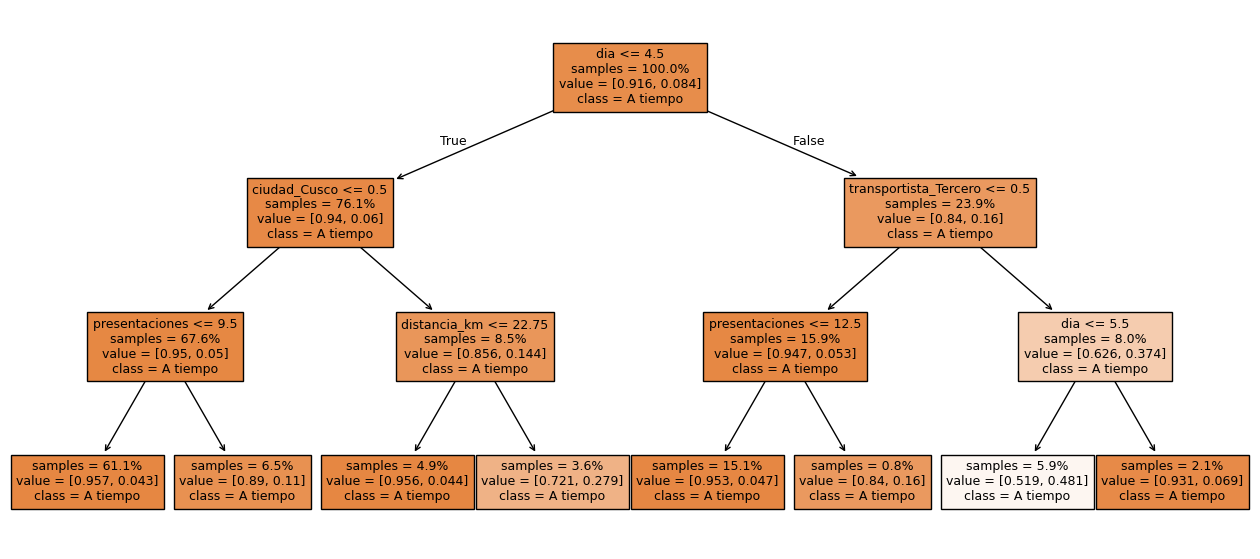

In [6]:
plt.figure(figsize=(16, 7))
plot_tree(
    arbol,
    feature_names=list(x_entreno.columns),
    class_names=["A tiempo", "Tarde"],
    proportion=True,
    impurity=False,
    filled=True,
    fontsize=9,
)
plt.show()

La primera pregunta es `dia <= 4.5`: ¿es de lunes a viernes? El árbol eligió solo esa pregunta, porque es la que mejor separa. Sigue el camino de la derecha: fin de semana, luego transportista tercero, luego `dia <= 5.5`, o sea, sábado.

Ahora fíjate en un detalle: **todas las hojas dicen "A tiempo"**. Ninguna pasa del 50 % de tardíos. Si solo miras el sí o el no, el árbol no sirve de nada. Lo útil es el **porcentaje** de cada hoja.

### Paso 4: cada hoja, un nivel de riesgo

`.predict_proba()` entrega el porcentaje de tardíos de la hoja donde cae cada despacho. Agrupamos por ese número:

In [7]:
riesgo = pd.Series(arbol.predict_proba(x_entreno)[:, 1], index=entreno.index).round(3)

entreno.groupby(riesgo)["llego_tarde"].agg(["size", "mean"]).sort_index(ascending=False).round(3)

,size,mean
0.481,1801,0.481
0.279,1095,0.279
0.160,257,0.160
0.110,1988,0.110
0.069,638,0.069
0.047,4608,0.047
0.044,1485,0.044
0.043,18644,0.043


Cada fila es una hoja: cuántos despachos tiene y qué parte llegó tarde. La de arriba, terceros en sábado, llega cerca del 48 %. La más común, cerca del 4 %. Es decir: **la hoja da un orden de prioridad**, y ya no hay que vigilarlo todo.

Lo mismo funciona en datos que el árbol no vio:

In [8]:
riesgo_prueba = pd.Series(arbol.predict_proba(x_prueba)[:, 1], index=prueba.index).round(3)

prueba.groupby(riesgo_prueba)["llego_tarde"].agg(["size", "mean"]).sort_index(
    ascending=False
).round(3)

,size,mean
0.481,623,0.515
0.279,433,0.203
0.160,101,0.248
0.110,767,0.203
0.069,252,0.071
0.047,1621,0.048
0.044,575,0.070
0.043,6949,0.043


El índice es el porcentaje que aprendió el árbol, y `mean` es lo que pasó de verdad en estos despachos nuevos. El orden se sostiene en los extremos, no en el medio: la hoja de 11 % sube a cerca de 20 %, y la de 28 % baja a cerca de 20 %. En parte es porque la prueba tiene casi el triple de despachos de julio y diciembre, y las hojas de pedidos grandes suben. Sirve para empezar por los de arriba, no como un número exacto.

### Qué tan lejos llega copiarlo a Excel

Este árbol, con 8 hojas, se puede escribir en un `=SI()` (`IF`). Uno con 6 preguntas puede tener decenas de hojas, y ya nadie lo copia a mano. Además, parte de sus cortes puede ser solo ruido.

Y un árbol no siempre es la mejor opción. En el próximo episodio vemos qué pasa si lo dejamos crecer.

## 🤖 Pídeselo a la IA

> *"Tengo un árbol de decisión con esta regla: `si dia > 4.5 y transportista_Tercero > 0.5 y dia <= 5.5, 48 % llegan tarde`. Tradúcela a una frase para mi jefe, y a una fórmula de Excel en español."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| `=SI()` (`IF`) anidado | `DecisionTreeClassifier(max_depth=3)` |
| Leer la fórmula | `plot_tree(arbol, ...)` |
| Porcentaje de tardíos por regla | `arbol.predict_proba(x)[:, 1]` |
| Ordenar por riesgo | `.sort_index(ascending=False)` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/01-arbol-de-decision/ejercicio.ipynb) y lee tu propio árbol. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/01-arbol-de-decision/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0